# 6장 — TD(0) Prediction, Q-learning과 SARSA

같은 Episode에서 MC와 TD의 학습 입력 차이를 확인하고 Q-learning으로 정책을 개선한다.
`TabularTD0PredictionLearner`와 `TabularQLearner`를 사용한다.

[원본 Notebook](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/notebooks/06_temporal_difference.ipynb) · [실습 대응표](README.md)
SARSA는 실제 Next Action을 명시적으로 전달하는 Learner로 실행한다. Off-policy SARSA는 아직 지원하지 않는다.
Expected SARSA는 §12에서 신규 Learner 없이 기존 컴포넌트의 조합으로 검증한다.
Double Q-learning은 §13에서 두 독립 Model의 조합으로 검증한다.

## 1. Import와 설정

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from modular_rl.data import Transition
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector, GreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule
from modular_rl.learner import TabularTD0PredictionLearner, TabularQLearner, MCPredictionLearner
from modular_rl.environment import make_dlfs4_gridworld_env, DLFS4_STATES, DLFS4_START_STATE, collect_episode
from modular_rl.dp import uniform_policy, policy_evaluation
from plotting import plot_grid

SEED, GAMMA, ALPHA, EPISODES = 7, 0.9, 0.01, 1000
torch.manual_seed(SEED)
plt.close('all')

## 2. TD(0) 한 번의 계산 — `td_eval.py`

$$y=r+\gamma(1-\text{terminated})V(s'),\quad\delta=y-V(s),\quad V(s)\leftarrow V(s)+\alpha\delta$$

V(1)=4, V(2)=10, r=1, γ=.9, α=.5이면 y=10, δ=6, 새 V(1)=7이다.
Target 생성과 갱신은 기존 Component가 계산한다. `Transition.to_batch()`으로 B=1로 변환한다.

In [2]:
demo_model = Model(IdentityRepresentation(), TabularVEstimator(3)).double()
demo_model.estimator.v_table.copy_(torch.tensor([0., 4., 10.]))
demo_td = TabularTD0PredictionLearner(demo_model, TD0TargetGenerator(.9), TabularVUpdateRule(.5))
delta = demo_td.learn(Transition(1, 0, 1., 2, False, False).to_batch())
assert delta.item() == 6 and demo_model.forward(1).values.v.item() == 7
print('signed TD error:', delta.item(), '| updated V(1):', demo_model.forward(1).values.v.item())

signed TD error: 6.0 | updated V(1): 7.0


## 3. 교재 환경과 독립적인 MC / TD Model

원본처럼 시작 `(2,0)`, Uniform Policy, γ=.9, α=.01, 1,000 Episode를 사용한다.
MC와 TD는 각기 다른 V를 갖는다. 둘 다 동일한 DP Vπ를 기준으로 비교한다.

In [3]:
env = make_dlfs4_gridworld_env(max_episode_steps=2000)
mdp = env.unwrapped.mdp
states = np.arange(mdp.n_states)
nonterminal = np.setdiff1d(states, mdp.terminal_states)
policy = uniform_policy(mdp)
reference = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-10)
assert reference.converged
action_rng = np.random.default_rng(SEED + 1)
select_action = lambda state: int(action_rng.choice(mdp.n_actions, p=policy[state]))
mc_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
td_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
mc = MCPredictionLearner(mc_model, MonteCarloReturnGenerator(GAMMA), visit_mode='every')
td = TabularTD0PredictionLearner(td_model, TD0TargetGenerator(GAMMA), TabularVUpdateRule(ALPHA))

## 4. 같은 Episode 학습 — MC는 전체, TD는 전이별

MC는 완료 Episode의 Return을 사용한다. TD는 전이를 시간 순서대로 B=1로 전달해 갱신한다.
여기서는 비교를 위해 이미 수집된 Episode를 처리한다. 환경 종료 전에 학습하는 Streaming Runner는 아니다.
잘린 Episode는 MC에 사용할 수 없으므로 비교 자체를 중단한다.

수집은 collect_episode의 Gymnasium reset/step 경로를 공유한다. 전이 모델은 Env만 참조하고 Learner는 경험만 본다.

In [4]:
history, steps = [], 0
try:
    for number in range(1, EPISODES + 1):
        episode = collect_episode(env, select_action, seed=SEED if number == 1 else None)
        if not episode.terminated:
            raise RuntimeError('Incomplete comparison episode: MC must not learn a partial return')
        mc.learn(episode)
        for transition in episode.transitions:
            td.learn(transition.to_batch())
        steps += len(episode)
        if number % 100 == 0:
            values = [model.forward(states).values.v.numpy() for model in (mc_model, td_model)]
            errors = [np.sqrt(np.mean((v[nonterminal] - reference.values[nonterminal]) ** 2)) for v in values]
            history.append((number, steps, *errors))
finally:
    env.close()
print(f'episodes={EPISODES} steps={steps} seed={SEED} gamma={GAMMA} alpha={ALPHA}')
print('RMSE(MC, TD):', np.round(errors, 4))

episodes=1000 steps=45188 seed=7 gamma=0.9 alpha=0.01
RMSE(MC, TD): [0.0317 0.0239]


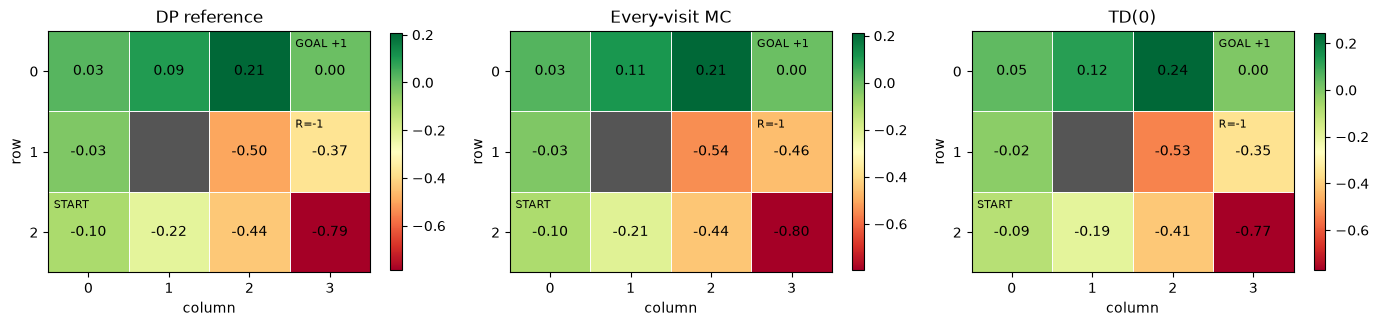

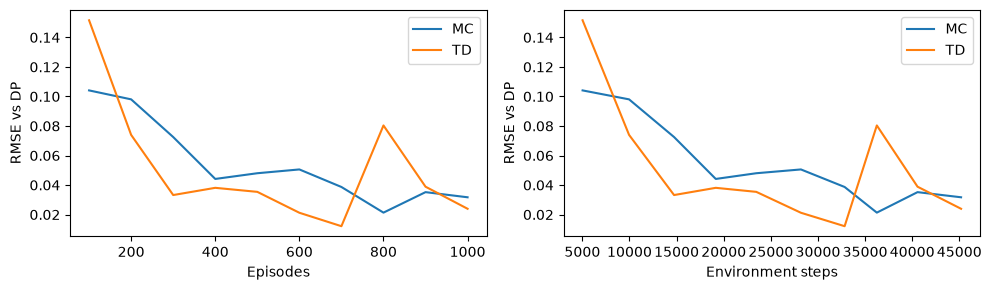

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, title, value in zip(axes, ('DP reference', 'Every-visit MC', 'TD(0)'), (reference.values, *values)):
    plot_grid(value, title=title, ax=ax)
plt.tight_layout(); plt.show()
history = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for column, label in ((2, 'MC'), (3, 'TD')):
    axes[0].plot(history[:, 0], history[:, column], label=label)
    axes[1].plot(history[:, 1], history[:, column], label=label)
axes[0].set(xlabel='Episodes', ylabel='RMSE vs DP')
axes[1].set(xlabel='Environment steps', ylabel='RMSE vs DP')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 5. B=1 Online와 B>1 Frozen Target Batch

`learn(batch)`는 **모든 Bootstrap Target을 갱신 전에 계산**한다. B>1에서 같은 상태가 반복되면
현재 V는 행 순서대로 갱신되지만 Target을 행 사이에 다시 계산하지 않는다.
위처럼 B=1로 호출하면 다음 전이의 Target은 이전 갱신을 반영한다.

예를 들어 V(1)=4, V(2)=10, γ=.9, α=.5이고 `(state,reward,next_state)`가 `(2,0,1)`, `(1,1,2)`이면
Batch의 error는 `[-6.4,6]`, 전이별 호출은 `[-6.4,3.12]`다. 두 계약은 회귀 테스트로 검증한다.

TD는 일반적인 Time-limit `truncated=True, terminated=False`에서 Bootstrap을 유지한다.
수집자가 reset된 관측 대신 실제 마지막 관측을 전달해야 한다. MC의 미완성 Episode 거절과 구분한다.
고정 α의 TD 오차와 표본 평균 MC 오차가 매 구간 감소하거나 특정 방법이 항상 우수할 필요는 없다.

## 6. SARSA — 실제 Next Action으로 Bootstrap

원본 sarsa.py는 Q(s′,a′)를 사용한다(γ=.9, α=.8, ε=.1, 10,000 Episode).
ModularRL은 Transition 필드를 바꾸지 않고 TabularSARSALearner.learn(batch, next_action=...)을 사용한다.
기존 TD(0)/Q-learning 실습 뒤의 §11에서 Step-by-step 학습과 비교를 실행한다.
실제 다음 행동을 선택한 뒤 학습하고, 그 행동을 다음 환경 step에서 그대로 실행한다.

## 7. Off-policy SARSA — 미구현 대응

원본 [`sarsa_off_policy.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch06/sarsa_off_policy.py)는 target/behavior 정책의 비율로
TD Target을 보정한다(γ=.9, α=.8, ε=.1, 10,000 Episode).
행동 확률의 저장 시점과 보정 규칙을 포함한 별도 Learner 계약이 필요하다. 이 실습은 실행 지원하지 않는다.

## 8. Q-learning — `q_learning.py`

$$y=r+\gamma(1-\text{terminated})\max_aQ(s',a)$$

행동 선택은 ε-greedy `Model.act()`, 학습은 `TabularQLearner.learn()`가 담당한다.
고정 정책의 V Prediction과 달리 Q에서 학습 중의 정책을 개선한다.

In [6]:
q_model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                EpsilonGreedyActionSelector(epsilon=.1)).double()
q_learner = TabularQLearner(q_model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(alpha=.8))
Q_EPISODES, MAX_STEPS = 1000, 200
q_env = make_dlfs4_gridworld_env(max_episode_steps=MAX_STEPS)

환경은 동일한 Gymnasium reset/step API로 실행한다. Outcome 선택과 TimeLimit 처리를 Notebook에 구현하지 않는다.
학습 수식은 Learner가 담당한다. 원본의 10,000 Episode 대신 간소화 예제와 같은 1,000 Episode로 실행한다.

In [7]:
reward_history, truncated_episodes = [], 0
try:
    for number in range(Q_EPISODES):
        observation, info = q_env.reset(seed=SEED if number == 0 else None)
        total_reward = 0.
        while True:
            selected = q_model.act(observation)
            next_observation, reward, terminated, truncated, info = q_env.step(selected.action.item())
            transition = Transition(observation, selected.action, reward, next_observation,
                                    terminated, truncated, selected.log_prob)
            q_learner.learn(transition.to_batch())
            observation = next_observation
            total_reward += reward
            if terminated or truncated:
                break
        truncated_episodes += int(truncated)
        reward_history.append(total_reward)
finally:
    q_env.close()
print(f'Q-learning: episodes={Q_EPISODES} seed={SEED} gamma={GAMMA} alpha=.8 epsilon=.1')
print('truncated:', truncated_episodes, '| last 100 mean reward:', np.mean(reward_history[-100:]))

Q-learning: episodes=1000 seed=7 gamma=0.9 alpha=.8 epsilon=.1
truncated: 0 | last 100 mean reward: 1.0


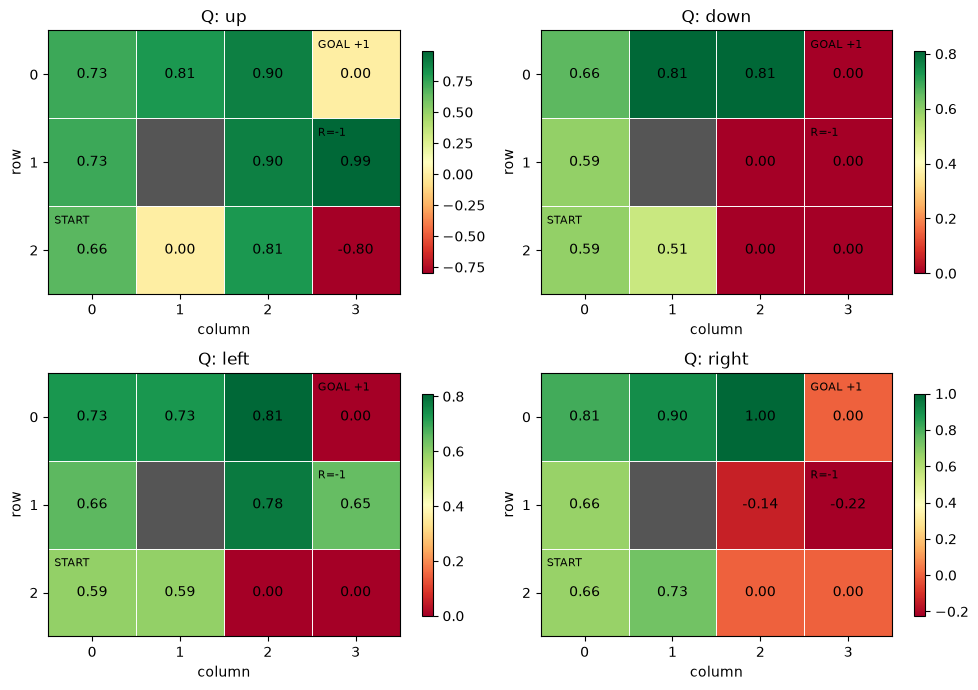

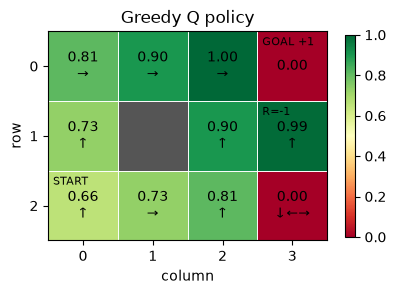

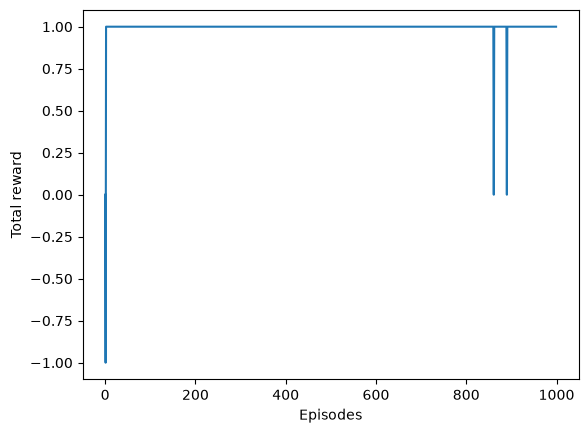

In [8]:
estimate = q_model.forward(states)
q_values = estimate.values.q[0].numpy()
greedy_policy = GreedyActionSelector().probabilities(estimate).numpy()
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for action, ax in enumerate(axes.flat):
    plot_grid(q_values[:, action], title=f'Q: {("up", "down", "left", "right")[action]}', ax=ax)
plt.tight_layout(); plt.show()
plot_grid(q_values.max(axis=-1), greedy_policy, title='Greedy Q policy')
plt.show()
plt.plot(reward_history)
plt.xlabel('Episodes'); plt.ylabel('Total reward'); plt.show()

## 9. Greedy Policy를 실행해 확인

In [9]:
eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
try:
    observation, info = eval_env.reset(seed=SEED)
    path = [DLFS4_STATES[observation]]
    while True:
        action = q_model.act(observation, deterministic=True).action.item()
        observation, reward, terminated, truncated, info = eval_env.step(action)
        path.append(DLFS4_STATES[observation])
        if terminated or truncated:
            break
finally:
    eval_env.close()
print('greedy path:', path, '| reached goal:', terminated)

greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)] | reached goal: True


## 10. `q_learning_simple.py`와의 대응

원본 두 Q-learning 예제의 업데이트는 같다. 위 Model + Learner가 두 예제를 함께 대체하므로
같은 학습 루프를 다시 복사하지 않는다. `Model.act()`는 행동과 Behavior log_prob를 함께 반환한다.
ModularRL의 학습 모드에서는 최대 Q 동률에 균등하게 탐색 확률을 주고 deterministic 모드는
가장 작은 인덱스를 택한다. 원본의 간소화 버전은 np.argmax로 첫 행동을 택한다.

SARSA·Off-policy SARSA의 미구현을 포함한 전체 대응 상태는 README 표에 기록했다.

고정 시작에서 방문이 적은 상태·행동의 Q는 0으로 남을 수 있다. 경로 성공이 모든 Q의 수렴을 뜻하지 않는다.

Env는 자연 종료 뒤 step을 거절한다. TimeLimit의 truncation 뒤에도 reset이 필요하며, 표준 Wrapper의 종료 flag를 보존한다. 정책 RNG와 Env RNG를 분리해 재실행 결정성을 검증한다.

## 11. SARSA — 실제 Next Action을 한 번 선택하고 그대로 실행

[Sutton & Barto Chapter 6](https://people.cs.umass.edu/~barto/courses/cs687/Chapter%206.pdf)의 On-policy TD Control이다.

$$y=r+\gamma(1-\mathrm{terminated})Q(s',a'),\quad\delta=y-Q(s,a)$$

Q-learning은 max Q(s′,·)를 사용하지만 SARSA는 **실제 행동 정책이 선택한 a′**를 사용한다.
TargetGenerator와 UpdateRule은 그대로 재사용한다. Learner 내부에서 행동을 선택하지 않는다.
Transition에 next_action을 추가하거나 Notebook에서 Target/Q 갱신을 재구현하지 않는다.

In [10]:
from modular_rl.learner import TabularSARSALearner

for next_action, terminated in ((1, False), (0, False), (None, True)):
    sarsa_demo_model = Model(IdentityRepresentation(), TabularQEstimator(4, 2)).double()
    sarsa_demo_model.estimator.q_table[1, 0] = 4
    sarsa_demo_model.estimator.q_table[2] = torch.tensor([10., 2.])
    sarsa_demo = TabularSARSALearner(sarsa_demo_model, TD0TargetGenerator(.9), TabularQUpdateRule(.5))
    error = sarsa_demo.learn(Transition(1, 0, 1., 2, terminated, False).to_batch(), next_action=next_action)
    print('next_action=', next_action, 'terminated=', terminated, 'TD error=', error.item(),
          'updated Q(1,0)=', sarsa_demo_model.estimator.q_table[1, 0].item())

next_action= 1 terminated= False TD error= -1.2000000000000002 updated Q(1,0)= 3.4
next_action= 0 terminated= False TD error= 6.0 updated Q(1,0)= 7.0
next_action= None terminated= True TD error= -3.0 updated Q(1,0)= 2.5


### Next Action과 Episode 경계

기본 next_action은 Batch와 같은 (B,) 정수 Tensor이며 B=1은 정수 scalar도 허용한다.
모든 행이 terminal이면 None을 허용한다. 혼합 Batch의 terminal 행에는 무시되는 유효 ID(예: 0)를 넣는다.
truncated-only는 마지막 관측에서 선택한 행동으로 Bootstrap하지만 그 행동을 종료된 환경에서 실행하지 않는다.
두 종료 flag가 모두 True면 Bootstrap하지 않는다. 실제 final observation은 수집자가 보존한다.

B>1은 모든 Target을 먼저 계산한 Frozen Target Batch Update다. 중복 쌍은 기존 Rule로 순차 갱신한다.
아래 Online SARSA는 B=1을 시간순으로 호출하고 a′를 학습 전에 선택해 다음 step까지 유지한다.

In [11]:
SARSA_EPISODES, SARSA_SEED, SARSA_ALPHA, SARSA_EPSILON = 1000, 7, .8, .1
torch.manual_seed(SARSA_SEED)
sarsa_model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                    EpsilonGreedyActionSelector(SARSA_EPSILON)).double()
sarsa = TabularSARSALearner(sarsa_model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(SARSA_ALPHA))
sarsa_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
sarsa_eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
sarsa_rewards, sarsa_lengths, sarsa_steps, sarsa_truncations = [], [], 0, 0
try:
    sarsa_before = collect_episode(sarsa_eval_env, lambda state: sarsa_model.act(state, deterministic=True).action.item(), seed=SARSA_SEED + 1)
    for number in range(SARSA_EPISODES):
        observation, _ = sarsa_env.reset(seed=SARSA_SEED if number == 0 else None)
        selected = sarsa_model.act(observation)
        episode_reward, episode_length = 0., 0
        while True:
            action = selected.action.item()
            log_prob = selected.log_prob.detach().cpu().clone()
            next_observation, reward, terminated, truncated, _ = sarsa_env.step(action)
            next_selected = None if terminated else sarsa_model.act(next_observation)
            next_action = None if next_selected is None else next_selected.action.item()
            transition = Transition(observation, action, reward, next_observation, terminated, truncated, log_prob)
            sarsa.learn(transition.to_batch(), next_action=next_action)
            episode_reward += reward
            episode_length += 1
            if terminated or truncated:
                break
            observation, selected = next_observation, next_selected  # Reuse the already selected action.
        sarsa_rewards.append(episode_reward)
        sarsa_lengths.append(episode_length)
        sarsa_steps += episode_length
        sarsa_truncations += int(truncated)
    sarsa_after = collect_episode(sarsa_eval_env, lambda state: sarsa_model.act(state, deterministic=True).action.item(), seed=SARSA_SEED + 1)
finally:
    sarsa_env.close()
    sarsa_eval_env.close()
print(f'SARSA: episodes={SARSA_EPISODES} steps={sarsa_steps} seed={SARSA_SEED} '
      f'gamma={GAMMA} alpha={SARSA_ALPHA} epsilon={SARSA_EPSILON} truncated={sarsa_truncations}')
print('before greedy: goal=', sarsa_before.terminated, 'steps=', len(sarsa_before))
print('after greedy: goal=', sarsa_after.terminated, 'steps=', len(sarsa_after), 'reward=', sum(t.reward.item() for t in sarsa_after.transitions))
print('last 100 training mean reward:', np.mean(sarsa_rewards[-100:]))

SARSA: episodes=1000 steps=8604 seed=7 gamma=0.9 alpha=0.8 epsilon=0.1 truncated=0
before greedy: goal= False steps= 20
after greedy: goal= True steps= 5 reward= 1.0
last 100 training mean reward: 1.0


### 같은 예산·설정으로 여러 Seed 비교

SARSA와 Q-learning은 서로 독립적인 Model/Learner/RNG 실행이다. 같은 Seed도 정책 변화와
행동 선택 시점이 달라 동일 Episode를 뜻하지 않는다. 두 알고리즘 모두 γ=.9, α=.8, ε=.1,
1,000 Episode를 사용한다. 작은 비교 루프는 환경 실행과 데이터 수집만 담당하며, 두 Learner의 공개 API로 학습한다.
학습 중 ε-greedy Reward/Length와 평가 시 Greedy Goal/Step을 구분한다.
고정 α와 유한 표본에서 한 Seed의 Greedy 평가가 실패할 수도 있다. 방법 간 성능 순위를 Assertion으로 고정하지 않는다.

In [12]:
from modular_rl.dp import value_iteration

comparison_optimal = value_iteration(mdp, gamma=GAMMA, theta=1e-12)

def run_td_control(algorithm, seed):
    """Small experiment loop: all target/update arithmetic stays in the learners."""
    torch.manual_seed(seed)
    model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                  EpsilonGreedyActionSelector(SARSA_EPSILON)).double()
    learner_type = TabularSARSALearner if algorithm == 'sarsa' else TabularQLearner
    learner = learner_type(model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(SARSA_ALPHA))
    train_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
    eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
    rewards, lengths = [], []
    try:
        for number in range(SARSA_EPISODES):
            observation, _ = train_env.reset(seed=seed if number == 0 else None)
            selected = model.act(observation)
            episode_reward, length = 0., 0
            while True:
                action = selected.action.item()
                next_observation, reward, terminated, truncated, _ = train_env.step(action)
                transition = Transition(observation, action, reward, next_observation, terminated, truncated)
                if algorithm == 'sarsa':
                    next_selected = None if terminated else model.act(next_observation)
                    learner.learn(transition.to_batch(), next_action=None if next_selected is None else next_selected.action.item())
                else:
                    learner.learn(transition.to_batch())
                    next_selected = None if terminated or truncated else model.act(next_observation)
                episode_reward += reward
                length += 1
                if terminated or truncated:
                    break
                observation, selected = next_observation, next_selected
            rewards.append(episode_reward)
            lengths.append(length)
        evaluation = collect_episode(eval_env, lambda state: model.act(state, deterministic=True).action.item(), seed=seed + 1)
    finally:
        train_env.close()
        eval_env.close()
    values = model.estimator.q_table.numpy().copy()
    return {'steps': sum(lengths), 'training_rewards': np.asarray(rewards), 'episode_lengths': np.asarray(lengths),
            'q_values': values, 'after': {'terminated': evaluation.terminated, 'steps': len(evaluation)},
            'max_q_rmse': np.sqrt(np.mean((values.max(axis=1)[nonterminal] - comparison_optimal.values[nonterminal])**2))}

comparison_results = {}
for comparison_seed in (7, 11, 19):
    for algorithm in ('sarsa', 'q_learning'):
        result = run_td_control(algorithm, comparison_seed)
        comparison_results[comparison_seed, algorithm] = result
        print(f"seed={comparison_seed} {algorithm}: steps={result['steps']} "
              f"train_reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
              f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
              f"maxQ_DP_RMSE={result['max_q_rmse']:.6f}")
np.testing.assert_array_equal(sarsa_model.estimator.q_table.numpy(), comparison_results[7, 'sarsa']['q_values'])
print('Direct SARSA loop and comparison loop produce the same Q at seed 7.')

seed=7 sarsa: steps=8604 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.375808


seed=7 q_learning: steps=5738 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.230544


seed=11 sarsa: steps=6659 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.300900


seed=11 q_learning: steps=5630 train_reward(last100)=0.980 goal=True greedy_steps=5 maxQ_DP_RMSE=0.069670


seed=19 sarsa: steps=6627 train_reward(last100)=1.000 goal=False greedy_steps=20 maxQ_DP_RMSE=0.255833


seed=19 q_learning: steps=5611 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.243963
Direct SARSA loop and comparison loop produce the same Q at seed 7.


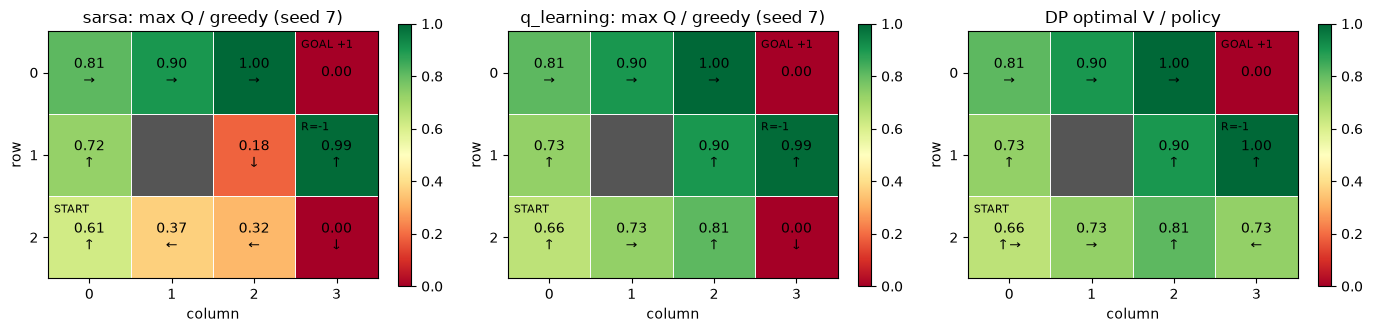

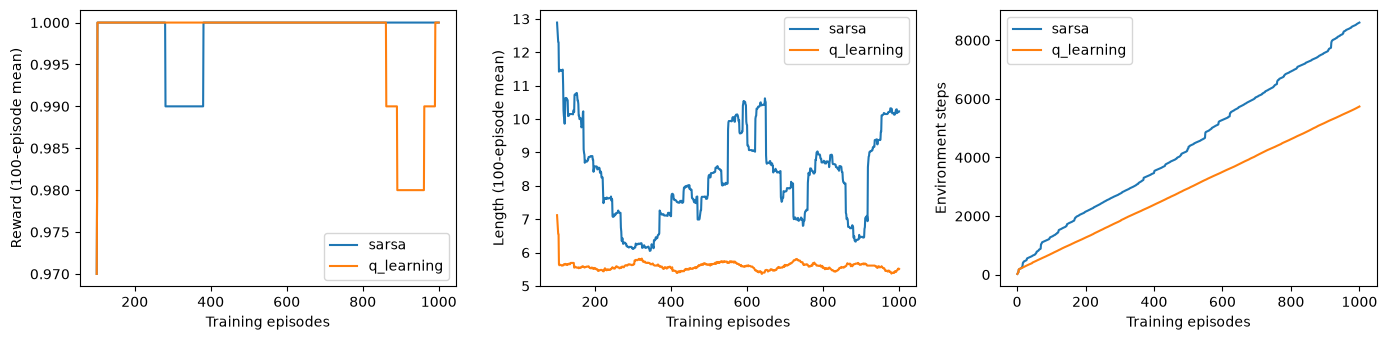

In [13]:
from modular_rl.dp import value_iteration

control_optimal = value_iteration(mdp, gamma=GAMMA, theta=1e-12)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, algorithm in zip(axes[:2], ('sarsa', 'q_learning')):
    values = comparison_results[7, algorithm]['q_values']
    policy = np.eye(mdp.n_actions)[values.argmax(axis=1)]
    plot_grid(values.max(axis=1), policy, title=f'{algorithm}: max Q / greedy (seed 7)', ax=ax)
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[2])
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for algorithm in ('sarsa', 'q_learning'):
    result = comparison_results[7, algorithm]
    episodes = np.arange(1, SARSA_EPISODES + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

SARSA는 탐색 행동도 Bootstrap에 포함하므로 학습 Q를 DP의 Q*와 같다고 가정하지 않는다.
이 비교의 RMSE는 Goal placeholder를 제외한 10개 상태의 max Q와 최적 V 차이다.
정확성은 실제 Next Action, 선택 횟수·실행 재사용, 종료 mask와 Batch/Online 차이의 결정적 테스트로 확인한다.
모델 저장·복원에는 기존 state_dict와 gamma/alpha·환경/행동 RNG 상태를 유지한다.
Off-policy SARSA와 n-step은 미구현이다. Expected SARSA는 다음 절의 예제 함수로 조합하며 라이브러리 Learner는 추가하지 않는다.

## 12. Expected SARSA — 기존 컴포넌트를 직접 조합

$$\bar Q(s')=\sum_a\pi(a\mid s')Q(s',a),\qquad
y=r+\gamma(1-\mathrm{terminated})\bar Q(s')$$

Q-learning은 max Q, SARSA는 실제 선택한 다음 행동의 Q, Expected SARSA는 행동 확률로 가중한 Q를 사용한다.
이번 실습은 **새 Learner와 새로운 TargetGenerator 없이** 실행한다.
`Model.forward → ActionSelector.probabilities → ΣπQ → TD0TargetGenerator → TabularQUpdateRule`을
작은 `examples/gridworld_expected_sarsa.py` 함수 한 곳에 작성했다. 아래 셀은 그 함수를 그대로 로드해 보여준다.
`examples`는 설치 패키지에 포함되지 않으므로 프로젝트 파일을 로드하며, sys.path나 라이브러리를 변경하지 않는다.

실제 행동을 고르는 Model의 **동일 Selector 객체**로 π를 조회한다. `probabilities()`는 행동을 샘플링하지 않고
RNG를 소비하지 않는다. 여기의 π는 학습 중 ε-greedy 정책이며 별도 Greedy 평가와 구분한다.
Q와 π는 한 번의 EstimatorOutput에서 읽고, Batch 전체의 Target을 갱신 전에 고정한다.

In [14]:
from pathlib import Path
import inspect
import runpy

expected_root = Path.cwd()
while not (expected_root / 'examples' / 'gridworld_expected_sarsa.py').is_file():
    if expected_root == expected_root.parent:
        raise FileNotFoundError('Open this tutorial inside the ModularRL project.')
    expected_root = expected_root.parent
expected_api = runpy.run_path(str(expected_root / 'examples' / 'gridworld_expected_sarsa.py'))
learn_expected_sarsa = expected_api['learn_expected_sarsa']
train_expected_comparison = expected_api['train_and_evaluate']
print(inspect.getsource(learn_expected_sarsa))

def learn_expected_sarsa(model: Model, batch: TransitionBatch, target_generator: TD0TargetGenerator,
                         update_rule: TabularQUpdateRule, *, policy_selector) -> Tensor:
    """Compose a frozen TD target and in-place Q update from an external batch.

    policy_selector must be the very object used by model.act, supporting
    discrete probabilities. Batch rows are (B,); states/actions are integer,
    rewards floating and boundary flags bool. Q/probabilities are (B,A) with
    equal dtype/device. The live table determines batch dtype/device.

    One estimate supplies both Q and pi before any writes. No action/RNG is
    sampled. Termination is masked by the existing target generator; time-limit
    truncation bootstraps from the collector's actual final observation.
    Existing sequential duplicate-pair updates return signed errors (B,) with
    no graph. This example function adds no library API or learning state.
    """
    _validate(model, batch, policy_selec

### ε와 종료 mask의 수치 검증

Q(s′,:)=[10,2], Q(s,a)=4, r=1, γ=.9, α=.5다.
ε=0이면 기대값은 10, ε=1이면 평균 6, ε=.2이면 π=[.9,.1]로 기대값은 9.2다.
동률 최대 행동에는 기존 Selector의 균등 Greedy 확률이 적용된다.
terminated는 Reward만 사용하고 truncated-only는 실제 마지막 관측에서 Bootstrap한다.
예제 함수는 no_grad에서 Target을 만들고 기존 Rule이 signed Error를 반환한다.

In [15]:
for epsilon, terminated, truncated in ((0., False, False), (1., False, False),
                                         (.2, False, False), (.2, True, False), (.2, False, True)):
    expected_demo = Model(IdentityRepresentation(), TabularQEstimator(3, 2),
                          EpsilonGreedyActionSelector(epsilon)).double()
    expected_demo.estimator.q_table[1, 0] = 4.
    expected_demo.estimator.q_table[2] = torch.tensor([10., 2.])
    rng_before = torch.random.get_rng_state().clone()
    error = learn_expected_sarsa(expected_demo, Transition(1, 0, 1., 2, terminated, truncated).to_batch(),
                                TD0TargetGenerator(.9), TabularQUpdateRule(.5),
                                policy_selector=expected_demo.action_selector)
    assert torch.equal(rng_before, torch.random.get_rng_state())
    print(f'epsilon={epsilon:.1f} terminated={terminated} truncated={truncated} '
          f'TD_error={error.item():.4f} Q={expected_demo.estimator.q_table[1, 0].item():.4f}; RNG unchanged')

epsilon=0.0 terminated=False truncated=False TD_error=6.0000 Q=7.0000; RNG unchanged
epsilon=1.0 terminated=False truncated=False TD_error=2.4000 Q=5.2000; RNG unchanged
epsilon=0.2 terminated=False truncated=False TD_error=5.2800 Q=6.6400; RNG unchanged
epsilon=0.2 terminated=True truncated=False TD_error=-3.0000 Q=2.5000; RNG unchanged
epsilon=0.2 terminated=False truncated=True TD_error=5.2800 Q=6.6400; RNG unchanged


### Gymnasium reset/step으로 B=1 Online 학습

다음은 첫 Episode를 직접 실행하는 흐름이다. 행동 샘플링과 환경 step은 호출자가 수행하고
수학적 계산은 위 예제 함수에만 있다. π 조회와 Q 업데이트가 끝난 뒤 다음 실행 행동을 샘플링한다.
SARSA의 학습 전 next_action 선택·유지와 달리 실제 a′가 Bootstrap에 필요하지 않다.
에피소드 경계에서 reset하고, truncated-only에서도 final observation을 그대로 사용한다.

In [16]:
torch.manual_seed(11)
expected_online = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                        EpsilonGreedyActionSelector(.1)).double()
expected_target, expected_update = TD0TargetGenerator(.9), TabularQUpdateRule(.8)
expected_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
expected_reward, expected_steps = 0., 0
try:
    observation, _ = expected_env.reset(seed=11)
    while True:
        selected = expected_online.act(observation)
        log_prob = selected.log_prob.detach().cpu().clone()
        next_observation, reward, terminated, truncated, _ = expected_env.step(selected.action.item())
        transition = Transition(observation, selected.action.item(), reward, next_observation,
                                terminated, truncated, log_prob)
        error = learn_expected_sarsa(expected_online, transition.to_batch(), expected_target, expected_update,
                                    policy_selector=expected_online.action_selector)
        expected_reward += reward
        expected_steps += 1
        if terminated or truncated:
            break
        observation = next_observation
finally:
    expected_env.close()
print(f'Expected SARSA online: episode=1 reward={expected_reward} length={expected_steps} '
      f'terminated={terminated} truncated={truncated}')

Expected SARSA online: episode=1 reward=1.0 length=41 terminated=True truncated=False


### 동일 하이퍼파라미터·Episode 예산으로 여러 Seed 비교

γ=.9, α=.8, ε=.1, 1,000 Episode, 시작 (2,0), 학습 TimeLimit 2,000 Step, Greedy 평가 20 Step이다.
세 방법은 독립 Model을 학습하며 동일 Seed가 동일 경험을 의미하지 않는다.
예제의 공통 환경 루프가 Expected SARSA 함수와 기존 Q-learning/SARSA Learner를 호출한다.
아래에서는 학습 코드를 다시 구현하지 않고 그 실험 함수를 사용한다.
Reward/Length와 누적 Step, 학습 후 Greedy 경로, DP 최적 경로, Q-table을 비교한다.

In [17]:
EXPECTED_EPISODES, EXPECTED_SEEDS = 1000, (7, 11, 19)
EXPECTED_ALGORITHMS = ('expected_sarsa', 'q_learning', 'sarsa')
expected_results = {}
for expected_seed in EXPECTED_SEEDS:
    for algorithm in EXPECTED_ALGORITHMS:
        _, result = train_expected_comparison(algorithm, episodes=EXPECTED_EPISODES, seed=expected_seed,
                                             gamma=.9, alpha=.8, epsilon=.1, max_steps=2000, log_every=0)
        expected_results[expected_seed, algorithm] = result
        print(f"seed={expected_seed} {algorithm}: episodes={result['episodes']} steps={result['steps']} "
              f"reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
              f"length(last100)={np.mean(result['episode_lengths'][-100:]):.2f} "
              f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
              f"training_cutoff={result['truncated_episodes']} maxQ_DP_RMSE={result['max_q_rmse']:.6f}")
        print('Greedy path:', [DLFS4_STATES[state] for state in result['after']['path']])
        with np.printoptions(precision=4, suppress=True):
            print('Q (up/down/left/right):\n', result['q_values'])
print('DP optimal:', expected_results[7, 'expected_sarsa']['dp_steps'], 'steps, V(start)=.6561')
for algorithm in ('q_learning', 'sarsa'):
    for expected_seed in EXPECTED_SEEDS:
        np.testing.assert_array_equal(expected_results[expected_seed, algorithm]['q_values'],
                                      comparison_results[expected_seed, algorithm]['q_values'])
print('Q-learning/SARSA Q tables match the unchanged earlier exercise.')

seed=7 expected_sarsa: episodes=1000 steps=53664 reward(last100)=0.990 length(last100)=5.64 goal=True greedy_steps=5 training_cutoff=23 maxQ_DP_RMSE=0.260824
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7033  0.6262  0.7033  0.7899]
 [ 0.7899  0.7899  0.7033  0.8871]
 [ 0.8871  0.7489  0.7899  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7033  0.5572  0.6262  0.6262]
 [ 0.8871  0.283   0.4463 -0.2189]
 [ 0.992   0.      0.     -0.2672]
 [ 0.6262  0.5572  0.5572  0.48  ]
 [ 0.377  -0.      0.5572  0.3397]
 [-0.0048 -0.0001  0.4687 -0.0144]
 [-0.8    -0.0144 -0.0003 -0.0147]]


seed=7 q_learning: episodes=1000 steps=5738 reward(last100)=1.000 length(last100)=5.51 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.230544
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.729   0.6561  0.729   0.81  ]
 [ 0.81    0.81    0.729   0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6561  0.6561]
 [ 0.9     0.      0.7774 -0.1395]
 [ 0.992   0.      0.648  -0.224 ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.      0.5102  0.5905  0.729 ]
 [ 0.81    0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]


seed=7 sarsa: episodes=1000 steps=8604 reward(last100)=1.000 length(last100)=10.23 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.375808
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5416  0.3011  0.2856  0.8098]
 [ 0.7126  0.7904  0.5141  0.9   ]
 [ 0.9     0.161   0.572   1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7236  0.2501  0.3005  0.3242]
 [ 0.      0.1845  0.     -0.2688]
 [ 0.992   0.      0.     -0.224 ]
 [ 0.6147  0.22    0.2979  0.4399]
 [ 0.331   0.1493  0.3687  0.1367]
 [ 0.0339  0.1093  0.3228  0.    ]
 [-0.8     0.      0.      0.    ]]


seed=11 expected_sarsa: episodes=1000 steps=5592 reward(last100)=0.950 length(last100)=5.39 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.050405
Greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.      0.497   0.      0.7378]
 [ 0.      0.      0.      0.8863]
 [ 0.8863  0.7666  0.7378  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.6254  0.      0.      0.    ]
 [ 0.8863  0.6804  0.7668 -0.1565]
 [ 1.      0.      0.6133  0.    ]
 [ 0.5206  0.5403  0.5404  0.6059]
 [ 0.6059  0.6059  0.5404  0.6805]
 [ 0.7669  0.6805  0.6059  0.582 ]
 [-0.1726  0.4373  0.6804  0.443 ]]


seed=11 q_learning: episodes=1000 steps=5630 reward(last100)=0.980 length(last100)=5.44 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.069670
Greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.      0.      0.      0.6387]
 [ 0.4147  0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.5314  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.128   0.5249  0.729   0.    ]]


seed=11 sarsa: episodes=1000 steps=6659 reward(last100)=1.000 length(last100)=6.75 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.300900
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5115  0.4444  0.4909  0.81  ]
 [ 0.5825  0.627   0.4908  0.9   ]
 [ 0.9     0.81    0.6927  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7266  0.3537  0.363   0.3952]
 [ 0.9     0.4478  0.5746 -0.8512]
 [ 0.      0.4392  0.      0.    ]
 [ 0.6279  0.368   0.3747  0.2974]
 [ 0.3169  0.3242  0.3674  0.3146]
 [-0.5436  0.0082  0.359   0.0912]
 [ 0.      0.0253  0.223   0.0253]]


seed=19 expected_sarsa: episodes=1000 steps=5621 reward(last100)=1.000 length(last100)=5.49 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.305310
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7033  0.6262  0.7033  0.7899]
 [ 0.7899  0.7899  0.7033  0.8871]
 [ 0.8871  0.7505  0.7899  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7033  0.5568  0.6262  0.6262]
 [ 0.8871  0.      0.5303  0.    ]
 [ 0.      0.      0.4301  0.    ]
 [ 0.6262  0.5568  0.5568  0.4635]
 [-0.     -0.      0.5568 -0.0003]
 [ 0.6004 -0.0003 -0.     -0.0144]
 [-0.8     0.     -0.0003 -0.0144]]


seed=19 q_learning: episodes=1000 steps=5611 reward(last100)=1.000 length(last100)=5.49 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.243963
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.729   0.6561  0.729   0.81  ]
 [ 0.81    0.81    0.729   0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6561  0.6561]
 [ 0.9     0.5832  0.     -0.4417]
 [ 0.      0.      0.7475  0.    ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.      0.      0.4724  0.729 ]
 [ 0.81    0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]


seed=19 sarsa: episodes=1000 steps=6627 reward(last100)=1.000 length(last100)=5.94 goal=False greedy_steps=20 training_cutoff=0 maxQ_DP_RMSE=0.255833
Greedy path: [(2, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0)]
Q (up/down/left/right):
 [[ 0.5218  0.5627  0.5832  0.4696]
 [ 0.5525  0.5286  0.5612  0.8398]
 [ 0.9     0.81    0.6258  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.5489  0.4225  0.5895  0.5717]
 [ 0.9     0.      0.648  -0.1088]
 [ 0.992   0.      0.      0.    ]
 [ 0.6346  0.3672  0.3843  0.3694]
 [ 0.2927  0.2114  0.5524  0.2622]
 [ 0.6804  0.      0.     -0.576 ]
 [-0.384   0.      0.      0.    ]]
DP optimal: 5 steps, V(start)=.6561
Q-learning/SARSA Q tables match the unchanged earlier exercise.


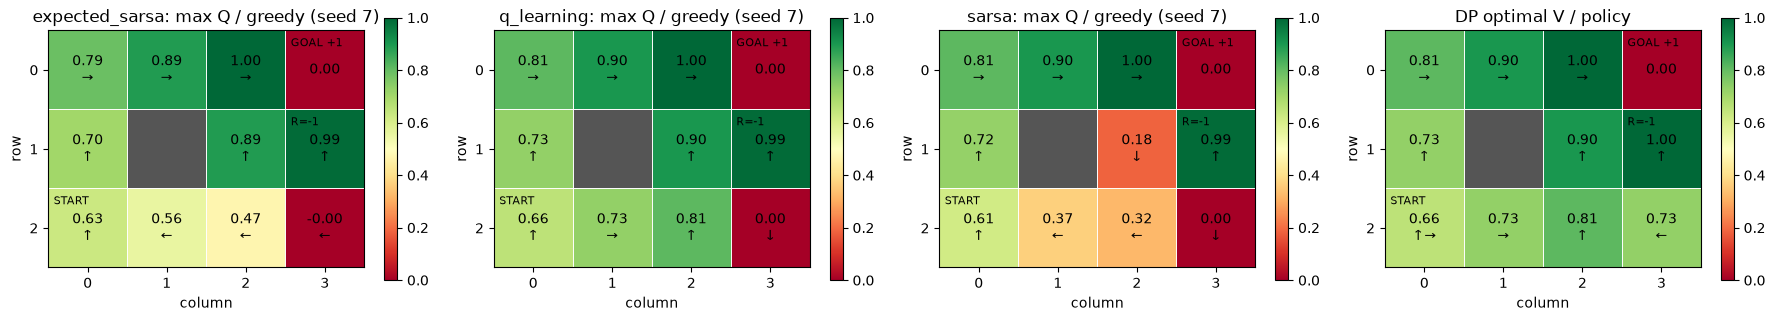

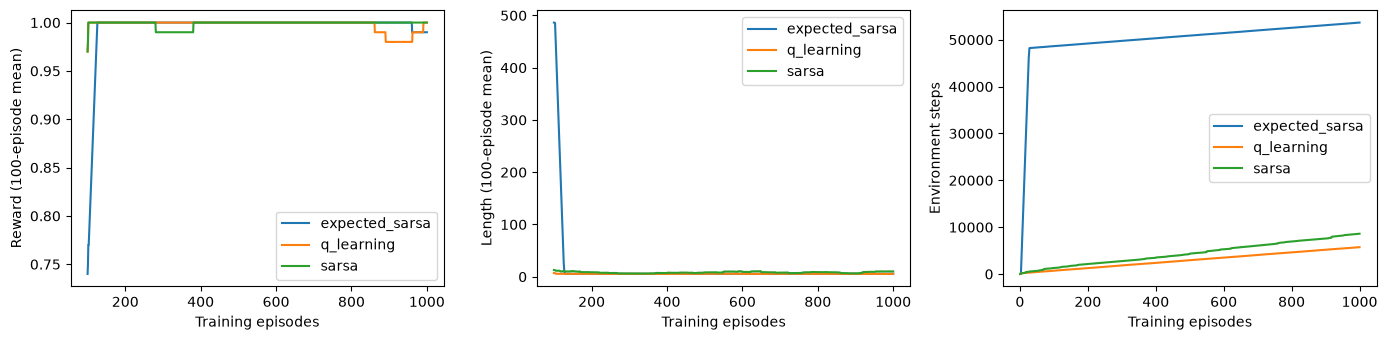

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, algorithm in zip(axes[:3], EXPECTED_ALGORITHMS):
    q = expected_results[7, algorithm]['q_values']
    greedy = np.eye(mdp.n_actions)[q.argmax(axis=1)]
    plot_grid(q.max(axis=1), greedy, title=f'{algorithm}: max Q / greedy (seed 7)', ax=ax)
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[3])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for algorithm in EXPECTED_ALGORITHMS:
    result = expected_results[7, algorithm]
    episodes = np.arange(1, EXPECTED_EPISODES + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

Expected SARSA의 세 Seed 모두 학습 후 5 Step/+1로 목표에 도달했다. Seed 7은 학습 초기에 23 Episode가
Time-limit으로 잘려 Step 비용이 컸다. SARSA Seed 19의 Greedy cutoff도 그대로 표시한다.
고정 α·유한 표본에서 순위나 모든 Q의 수렴을 보장하지 않는다. Expected/SARSA의 ε-greedy Q를 Q*와
동일하다고 간주하지 않으며, max Q와 최적 V의 RMSE는 비교 지표다.

기존 Learner의 Bootstrap은 max/gather로 고정돼 있다. 이번 검증은 **출력 계약은 재사용 가능하지만
Learner의 조합 경로는 고정돼 있음**을 보여준다. TD0TargetGenerator는 이미 계산된 next_value만 받으므로
새 TargetGenerator로 π/Q 선택 책임을 옮길 필요가 없다. 향후 공통화 후보는 외부에서 계산한 next_value (B,)를
받는 작은 Tabular Target/Update 조합이며, 이번에는 그 인터페이스나 공통 Base Class를 추가하지 않는다.
예제에는 학습 상태가 따로 없고 Q/ε는 Model.state_dict에 포함된다. 재개 시 γ/α와 환경·Torch RNG도 보존한다.

## 13. Double Q-learning — 선택과 평가를 서로 다른 Q로 수행

Q-learning은 같은 추정치로 최댓값 행동을 고르고 그 가치를 평가한다.
추정 오차가 있는 행동들 중 큰 값을 선택하면 Max가 실제 가치보다 커질 수 있다(Maximization Bias).
Double Q-learning은 두 개의 독립 Q-table을 두고 선택과 평가를 교차한다.

$$a^*=\arg\max_a Q_1(s',a),\quad y_1=r+\gamma(1-\mathrm{terminated})Q_2(s',a^*)$$
$$Q_1(s,a)\leftarrow Q_1(s,a)+\alpha[y_1-Q_1(s,a)]$$

Q₂ 갱신은 두 역할을 바꾼다. 매 Step마다 독립 동전을 던져 **하나의 테이블만** 갱신한다.
Behavior와 Greedy 평가에는 **Q₁+Q₂**를 사용한다. Bootstrap argmax 동률은 최소 행동 ID,
Behavior 동률은 기존 Selector의 균등 샘플링이다.

새 Learner나 합산용 영구 Q-table을 만들지 않는다. 기존 Model.forward 두 결과를 더해
`EstimatorOutput(values=ValueOutput(q=(q1+q2,)))`로 기존 Selector에 전달한다.
기존 Model.act는 하나의 Estimator를 사용하므로 여기서는 Selector.select를 공개 API로 직접 호출한다.
다음 셀은 예제 파일의 같은 함수를 로드해 표시한다. Notebook에서 교차 Target 계산을 다시 정의하지 않는다.

In [19]:
double_root = Path.cwd()
while not (double_root / 'examples' / 'gridworld_double_q_learning.py').is_file():
    if double_root == double_root.parent:
        raise FileNotFoundError('Open this tutorial inside the ModularRL project.')
    double_root = double_root.parent
double_api = runpy.run_path(str(double_root / 'examples' / 'gridworld_double_q_learning.py'))
combined_estimate = double_api['combined_estimate']
act_double_q = double_api['act_double_q']
choose_update_first = double_api['choose_update_first']
learn_double_q = double_api['learn_double_q']
train_double_comparison = double_api['train_and_evaluate']
for function in (combined_estimate, act_double_q, learn_double_q):
    print(inspect.getsource(function))

@torch.no_grad()
def combined_estimate(model1: Model, model2: Model, observation) -> EstimatorOutput:
    """Combine live Q estimates into one explicit Q sum, without a third table.

    Integer observations may be single or batched. The result has Q shape
    (..., A). The existing selector receives one tensor, not two unreduced
    critics. Behavior and greedy evaluation both use Q1 + Q2.
    """
    _validate_models(model1, model2)
    q1, = model1.forward(observation).values.q
    q2, = model2.forward(observation).values.q
    if q1.shape != q2.shape:
        raise ValueError("Q estimates must have the same shape without broadcasting")
    return EstimatorOutput(values=ValueOutput(q=(q1 + q2,)))

def act_double_q(model1: Model, model2: Model, observation, selector: EpsilonGreedyActionSelector,
                 *, deterministic=False) -> ActionOutput:
    """Use the unchanged selector's sampling, ties, probabilities and log_prob."""
    return selector.select(combined_estimate(model

### 교차 Bootstrap 수치 검증

Q₁(s′,:)=[10,2], Q₂(s′,:)=[1,7], 현재 Q₁(s,a)=4, Q₂(s,a)=6이다.
r=1, γ=.9, α=.5에서 Q₁을 갱신하면 a*=0, Bootstrap=1, Target=1.9,
Error=−2.1, 새 Q₁=2.95다. Q₂ 갱신은 a*=1, Bootstrap=2,
Target=2.8, Error=−3.2, 새 Q₂=4.4다. 반대 테이블은 유지한다.

In [20]:
for update_first in (True, False):
    double_demo = tuple(Model(IdentityRepresentation(), TabularQEstimator(3, 2)).double() for _ in range(2))
    double_demo[0].estimator.q_table[1, 0] = 4.
    double_demo[1].estimator.q_table[1, 0] = 6.
    double_demo[0].estimator.q_table[2] = torch.tensor([10., 2.])
    double_demo[1].estimator.q_table[2] = torch.tensor([1., 7.])
    other = double_demo[1 if update_first else 0].estimator.q_table.clone()
    error = learn_double_q(*double_demo, Transition(1, 0, 1., 2, False, False).to_batch(),
                          TD0TargetGenerator(.9), TabularQUpdateRule(.5), update_first=update_first)
    torch.testing.assert_close(double_demo[1 if update_first else 0].estimator.q_table, other, rtol=0, atol=0)
    print(f'update_first={update_first}: TD_error={error.item():.4f} '
          f'Q1={double_demo[0].estimator.q_table[1, 0].item():.4f} '
          f'Q2={double_demo[1].estimator.q_table[1, 0].item():.4f}; other table unchanged')

update_first=True: TD_error=-2.1000 Q1=2.9500 Q2=6.0000; other table unchanged
update_first=False: TD_error=-3.2000 Q1=4.0000 Q2=4.4000; other table unchanged


### Gymnasium Step-by-step Online 학습과 RNG

환경은 reset(seed=seed)의 자체 NumPy RNG, 행동은 torch.manual_seed(seed)의 PyTorch RNG,
갱신 대상은 별도 default_rng(seed+2)를 사용한다. Evaluation은 deterministic으로 두 학습 RNG를 소비하지 않는다.
다음은 한 Episode를 직접 학습한다. Behavior log_prob은 Q₁+Q₂의 sampling-time 값이다.
terminated에서만 Bootstrap을 제거하고 truncated-only에서는 실제 마지막 관측을 사용한다.
B>1 호출을 사용할 때 update_first는 Batch 전체의 한 테이블을 지정하며 모든 Target은 첫 갱신 전에 고정된다.

In [21]:
torch.manual_seed(11)
double_models = tuple(Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions)).double() for _ in range(2))
double_selector = EpsilonGreedyActionSelector(.1).double()
double_target, double_update = TD0TargetGenerator(.9), TabularQUpdateRule(.8)
double_update_rng = np.random.default_rng(13)
double_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
double_reward, double_steps, double_counts = 0., 0, [0, 0]
try:
    observation, _ = double_env.reset(seed=11)
    while True:
        selected = act_double_q(*double_models, observation, double_selector)
        log_prob = selected.log_prob.detach().cpu().clone()
        next_observation, reward, terminated, truncated, _ = double_env.step(selected.action.item())
        transition = Transition(observation, selected.action.item(), reward, next_observation, terminated, truncated, log_prob)
        update_first = choose_update_first(double_update_rng)
        error = learn_double_q(*double_models, transition.to_batch(), double_target, double_update, update_first=update_first)
        double_counts[0 if update_first else 1] += 1
        double_reward += reward
        double_steps += 1
        if terminated or truncated:
            break
        observation = next_observation
finally:
    double_env.close()
print(f'Double Q online: episode=1 reward={double_reward} length={double_steps} '
      f'terminated={terminated} truncated={truncated} Q1/Q2_updates={double_counts}')

Double Q online: episode=1 reward=1.0 length=41 terminated=True truncated=False Q1/Q2_updates=[16, 25]


### Q-learning과 동일 예산으로 비교

γ=.9, α=.8, ε=.1, 각 1,000 Episode, Seed7/11/19다. Double Q는 독립 환경에서 새로 학습하고,
Q-learning/SARSA/Expected SARSA는 §12에서 동일 설정으로 실행한 결과를 그대로 재사용한다.
동일 Seed가 동일 경험을 의미하지 않는다. 학습 Reward/Length와 Greedy 평가를 구분한다.

행동에는 Q₁+Q₂를 쓰지만 가치 비교에는 **max((Q₁+Q₂)/2)**를 사용한다.
합산 Q 자체를 DP V*와 비교하면 스케일이 두 배가 되어 의미가 달라진다.

In [22]:
double_results = {}
for double_seed in (7, 11, 19):
    _, result = train_double_comparison(episodes=1000, seed=double_seed, gamma=.9, alpha=.8,
                                       epsilon=.1, max_steps=2000, log_every=0)
    double_results[double_seed] = result
    print(f"seed={double_seed} double_q: episodes={result['episodes']} steps={result['steps']} "
          f"reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
          f"length(last100)={np.mean(result['episode_lengths'][-100:]):.2f} "
          f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
          f"training_cutoff={result['truncated_episodes']} avgQ_DP_RMSE={result['max_q_rmse']:.9g} "
          f"Q1/Q2_updates={result['update_counts'].tolist()}")
    print('Double Q greedy path:', [DLFS4_STATES[state] for state in result['after']['path']])
    print('DP optimal path:', [DLFS4_STATES[state] for state in result['dp_path']])
    with np.printoptions(precision=4, suppress=True):
        print('Q1 (up/down/left/right):\n', result['q1_values'])
        print('Q2 (up/down/left/right):\n', result['q2_values'])
    for algorithm in ('q_learning', 'sarsa', 'expected_sarsa'):
        reference_run = expected_results[double_seed, algorithm]
        print(f"  {algorithm}: steps={reference_run['steps']} reward(last100)={np.mean(reference_run['training_rewards'][-100:]):.3f} "
              f"length(last100)={np.mean(reference_run['episode_lengths'][-100:]):.2f} "
              f"goal={reference_run['after']['terminated']} greedy_steps={reference_run['after']['steps']} "
              f"maxQ_DP_RMSE={reference_run['max_q_rmse']:.6f}")

seed=7 double_q: episodes=1000 steps=6017 reward(last100)=0.990 length(last100)=5.62 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=2.44923734e-09 Q1/Q2_updates=[3044, 2973]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.81  ]
 [ 0.      0.      0.5832  0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.4829  0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.5207  0.     -0.08  ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.7288  0.6561  0.6561]
 [-0.0802 -0.576   0.729   0.6068]]
Q2 (up/down/left/right):
 [[ 0.5832  0.      0.      0.81  ]
 [ 0.648   0.648   0.5832  0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.      0.      0.5244]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.     -0.8  

seed=11 double_q: episodes=1000 steps=5790 reward(last100)=0.990 length(last100)=5.58 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=0.148031751 Q1/Q2_updates=[2872, 2918]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.    ]
 [ 0.4977  0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.8097 -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.5314  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.24    0.5249  0.729   0.    ]]
Q2 (up/down/left/right):
 [[ 0.      0.      0.      0.7257]
 [ 0.622   0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.      0.    ]

seed=19 double_q: episodes=1000 steps=5796 reward(last100)=0.970 length(last100)=5.44 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=1.39409542e-08 Q1/Q2_updates=[2868, 2928]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.81  ]
 [ 0.648   0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.24    0.      0.729   0.    ]]
Q2 (up/down/left/right):
 [[ 0.      0.      0.5832  0.81  ]
 [ 0.      0.648   0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.4025  0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.      0.  

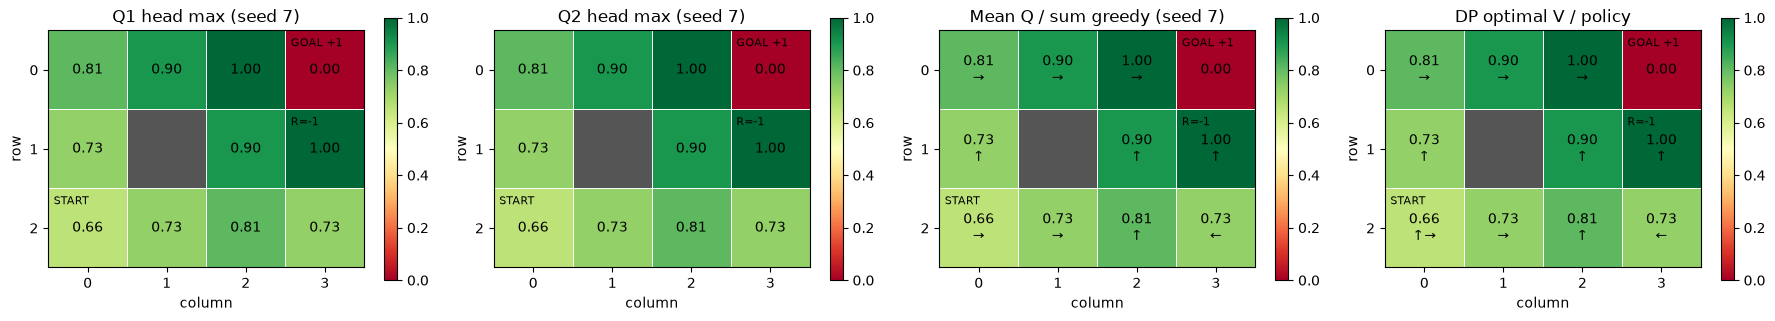

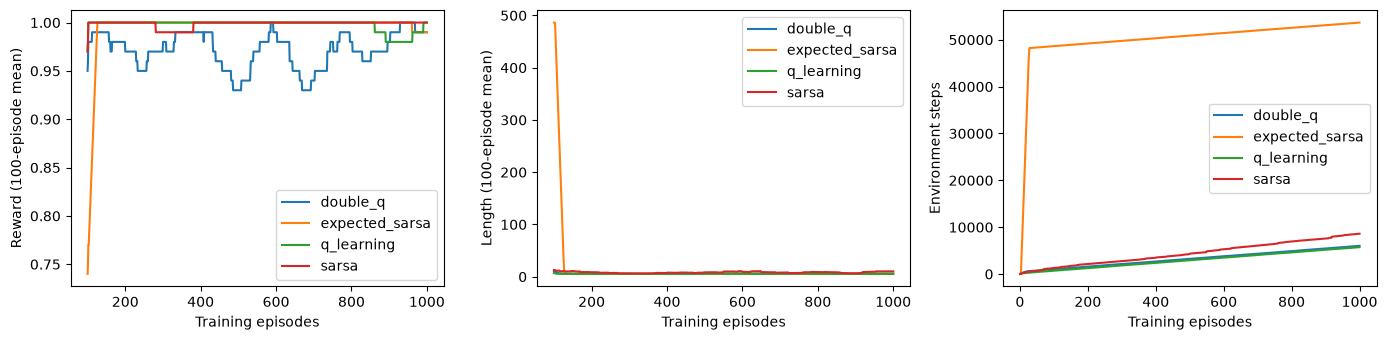

In [23]:
double_display = double_results[7]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
plot_grid(double_display['q1_values'].max(axis=1), title='Q1 head max (seed 7)', ax=axes[0])
plot_grid(double_display['q2_values'].max(axis=1), title='Q2 head max (seed 7)', ax=axes[1])
sum_q = double_display['q1_values'] + double_display['q2_values']
sum_greedy = np.eye(mdp.n_actions)[sum_q.argmax(axis=1)]
plot_grid(double_display['q_values'].max(axis=1), sum_greedy, title='Mean Q / sum greedy (seed 7)', ax=axes[2])
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[3])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
comparison_runs = {'double_q': double_display, **{algorithm: expected_results[7, algorithm] for algorithm in EXPECTED_ALGORITHMS}}
for algorithm, result in comparison_runs.items():
    episodes = np.arange(1, len(result['episode_lengths']) + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

### Maximization Bias 교재 실험의 표현 한계

[Sutton & Barto §6.7, Example 6.7, pp.134–136](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=156)의
A에는 두 행동이 있다. right는 보상 0으로 종료하고 left는 보상 0으로 B에 간다.
B의 여러 행동은 평균 −.1·분산 1의 정규분포 보상으로 종료한다.

현재 TabularMDP는 유한 Outcome의 **고정 Scalar 보상**과 모든 상태의 **동일 행동 수**를 표현한다.
TabularEnv에는 연속 Reward Sampler와 상태별 유효 행동 mask가 없다. 원본 분포/정책을 정확히
재현하려면 이 계약을 확장해야 하므로 이번 실험은 제외한다. 유한 보상 근사나 중복 행동을 원본 실험으로 부르지 않는다.
Gridworld 결과만으로 Maximization Bias가 일반적으로 제거됐다고 결론내리지 않는다.

두 Model과 기존 Selector/TargetGenerator/UpdateRule은 재사용할 수 있었다. Model은 하나의 Estimator를
조합하므로 두 forward 결과를 합산하는 예제 함수가 필요했고, 추가 클래스나 동기화용 Q-table은 필요 없었다.
향후 최소 공통화 후보는 명시적인 Q 출력 결합 함수와 외부 next_value를 받는 Target/Update 조합이다.
이번에는 라이브러리 인터페이스나 공통 프레임워크를 추가하지 않는다.

Checkpoint는 두 Model.state_dict, 별도 Selector.state_dict(ε), γ/α, Torch RNG, 갱신 RNG를 함께 저장한다.
환경 실행을 재개할 때는 환경 RNG와 Episode 위치도 수집자가 관리한다. 이번 함수에는 숨겨진 Learner 통계가 없다.
유한 표본의 성능 순위를 고정하지 않고 수학·독립 저장 공간·갱신 횟수·확률·복원 재현성을 결정적으로 검증한다.